# Tutorial

In [1]:
import matplotlib.pyplot as plt
from matplotlib.legend import Legend
import matplotlib.colors as colors

import numpy as np

import pandas as pd
import healpy as hp

from astropy.io import fits
from astropy import units as u
from astropy.coordinates import angular_separation

import time

# We import the script with all the density functions needed
import DM_density_profile_functions as density
import Jfactor_functions as J_factor

import matplotlib
matplotlib.rcParams.update(matplotlib.rcParamsDefault)

plt.rcParams['font.size'] = 13
plt.rc('text', usetex=True)
plt.rc('legend',fontsize=13) # using a size in points
plt.close('all')

matplotlib.rcParams['mathtext.fontset'] = 'custom'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['mathtext.fontset'] = 'cm'
matplotlib.rcParams['font.family'] = 'serif'

## DM Profiles Definition

#### Profiles allowed:
- Einasto
- NFW
- Generalized NFW
- Burkert
- Adiabatic Spike (Given by Gondolo&Silk 1999)
- Stars-Spike (for more information, see Zuriaga-Puig et al. 2023)
- Arbitrary Spike (for an arbitrary slope and spike radius)

Note that to definde the profile only a few of the parameters are needed, the rest are computed. We can define, for example, rho_sun or rho_s:

In [2]:
Profiles_List = {}

Profiles_List[0] = {'label' : r'NFW $\gamma = 1$',
    'Name_terminal': 'NFW',
    
   'rho_sun' : 0.4, # GeV cm-3
   'R_sun' : 8.277, # kpc
   'r_s' : 20, # kpc
   'R_vir' : 260, # kpc
   'alpha' : 1, # no units
   'beta' : 3, # no untis
   'gamma' : 1, # no units

   'R_sat' : None, # kpc
   'rho_sat' : 4.32e12, # GeV cm-3
   'slope_sat' : 0.5, # no units

   'Mode' : 'NFW', # 'NFW', 'Adiabatic_Spike', 'Stars_Spike', 'Arbitrary_Spike', 'Einasto'
   
   'Arbitrary_Slope' : None, # no units
   'R_spike' : None, # kpc
   'theta_spike' : None, # deg
   
   'color': 'blue', # color representation
   'ls': '-', # ls representation
  }


Profiles_List[1] = {'label' : r'gNFW $\gamma = 0.7$',
    'Name_terminal': 'NFW_0.7',
    
   'rho_sun' : 0.4, # GeV cm-3
   'R_sun' : 8.277, # kpc
   'r_s' : 20, # kpc
   'R_vir' : 260, # kpc
   'alpha' : 1, # no units
   'beta' : 3, # no untis
   'gamma' : 0.7, # no units

   'R_sat' : None, # kpc
   'rho_sat' : 4.32e12, # GeV cm-3
   'slope_sat' : 0.5, # no units

   'Mode' : 'NFW', # 'NFW', 'Adiabatic_Spike', 'Stars_Spike', 'Arbitrary_Spike', 'Einasto'
   
   'Arbitrary_Slope' : None, # no units
   'R_spike' : None, # kpc
   'theta_spike' : None, # deg
   
   'color': 'midnightblue', # color representation
   'ls': '-', # ls representation
  }

Profiles_List[2] = {'label' : r'Adiabatic Spike', #' $\gamma = 1$',
    'Name_terminal': 'Adiabatic_Spike',
    
   'rho_sun' : 0.4, # GeV cm-3
   'R_sun' : 8.277, # kpc
   'r_s' : 20, # kpc
   'R_vir' : 260, # kpc
   'alpha' : 1, # no units
   'beta' : 3, # no untis
   'gamma' : 1, # no units

   'R_sat' : None, # kpc
   'rho_sat' : 4.32e12, # GeV cm-3
   'slope_sat' : 0.5, # no units

   'Mode' : 'Adiabatic_Spike', # 'NFW', 'Adiabatic_Spike', 'Stars_Spike', 'Arbitrary_Spike', 'Einasto'
   
   'Arbitrary_Slope' : None, # no units
   'R_spike' : None, # kpc
   'theta_spike' : None, # deg
   
   'color': 'purple', # color representation
   'ls': '-.', # ls representation
  }


Profiles_List[3] = {'label' : r'Stars-Spike', #'$\gamma = 1$',
    'Name_terminal': 'Stars_Spike',
    
   'rho_sun' : 0.4, # GeV cm-3
   'R_sun' : 8.277, # kpc
   'r_s' : 20, # kpc
   'R_vir' : 260, # kpc
   'alpha' : 1, # no units
   'beta' : 3, # no untis
   'gamma' : 1, # no units

   'R_sat' : None, # kpc
   'rho_sat' : 4.32e12, # GeV cm-3
   'slope_sat' : 0.5, # no units

   'Mode' : 'Stars_Spike', # 'NFW', 'Adiabatic_Spike', 'Stars_Spike', 'Arbitrary_Spike', 'Einasto'
   
   'Arbitrary_Slope' : None, # no units
   'R_spike' : None, # kpc
   'theta_spike' : None, # deg
   
   'color': 'crimson', # color representation
   'ls': '--', # ls representation
  }



Profiles_List[4] = {'label' : 'Einasto',
    'Name_terminal': 'Einasto',
    
   'rho_sun' : 0.4, # GeV cm-3
   'R_sun' : 8.277, # kpc
   'r_s' : 20, # kpc
   'R_vir' : 260, # kpc
   'alpha' : 0.17, # no units
   'beta' : None, # no untis
   'gamma' : None, # no units

   'R_sat' : None, # kpc
   'rho_sat' : 4.32e12, # GeV cm-3
   'slope_sat' : 0.5, # no units

   'Mode' : 'Einasto', # 'NFW', 'Adiabatic_Spike', 'Stars_Spike', 'Arbitrary_Spike', 'Einasto', 'Burkert'
   
   'Arbitrary_Slope' : None, # no units
   'R_spike' : None, # kpc
   'theta_spike' : None, # deg
   
   'color': 'green', # color representation
   'ls': ':', # ls representation
  }

Profiles_List[5] = {'label' : 'Burkert',
    'Name_terminal': 'Burkert',
    
   'rho_sun' : 0.4, # GeV cm-3
   'R_sun' : 8.277, # kpc
   'r_s' : 12.67, # kpc
   'R_vir' : 260, # kpc
   'alpha' : None, # no units
   'beta' : None, # no untis
   'gamma' : None, # no units

   'R_sat' : None, # kpc
   'rho_sat' : 4.32e12, # GeV cm-3
   'slope_sat' : 0.5, # no units

   'Mode' : 'Burkert', # 'NFW', 'Adiabatic_Spike', 'Stars_Spike', 'Arbitrary_Spike', 'Einasto', 'Burkert'
   
   'Arbitrary_Slope' : None, # no units
   'R_spike' : None, # kpc
   'theta_spike' : None, # deg
   
   'color': 'coral', # color representation
   'ls': (0, (3, 1, 1, 1, 1, 1)), # ls representation
  }




#### The rest of parameters must be converted/computed

Needs to be done once always!

In [3]:
for i in range(len(Profiles_List)):
    Profiles_List[i] = density.parameters.parameters_computation(Profiles_List[i])

/Users/jaumezuriaga/anaconda3/lib/python3.10/site-packages/scipy/optimize/_minpack_py.py:177: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last ten iterations.
  warnings.warn(msg, RuntimeWarning)
/Users/jaumezuriaga/Desktop/DOCTORADO/Gammapy-Jfactory/gammapy/Notebooks_Jfactor_tutorial/DM_density_profile_functions.py:237: RuntimeWarning: invalid value encountered in power
  return rho_s /( (r/r_s)**gamma * (1 + (r/r_s)**alpha )**((beta-gamma)/alpha) )
/Users/jaumezuriaga/Desktop/DOCTORADO/Gammapy-Jfactory/gammapy/Notebooks_Jfactor_tutorial/DM_density_profile_functions.py:112: RuntimeWarning: invalid value encountered in power
  return rho_s * np.exp((-2 / alpha) * ((r / r_s) ** alpha - 1)) - rho_sat


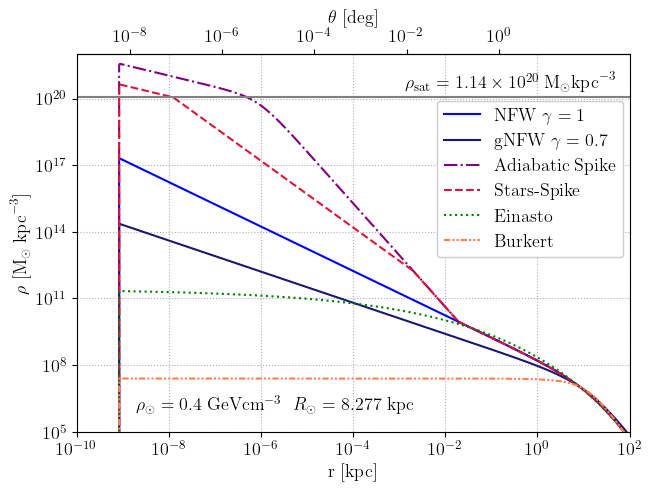

In [4]:
R_array = np.logspace(-10, 2, 1000)

fig, ax = plt.subplots(constrained_layout=True)

for i in range(len(Profiles_List)):
    ax.plot(R_array, density.profiles.rho_DM(R_array, Profiles_List[i]), label = Profiles_List[i]['label'],
             ls = Profiles_List[i]['ls'], color = Profiles_List[i]['color'])


R_sun = Profiles_List[0]['R_sun']
rho_sun = Profiles_List[0]['rho_sun']
rho_sat = Profiles_List[0]['rho_sat']


ax.text(2e-9, 1e6, r'$\rho_\odot = ' + str(rho_sun) + '\; \mathrm{GeV} \mathrm{cm}^{-3}$', horizontalalignment='left')
ax.text(5e-6, 1e6, r'$R_\odot = ' + str(R_sun) + '$ kpc', horizontalalignment='left')

formatted_number = "{:.2e}".format(rho_sat)  # da formato en notación científica con 2 decimales
formatted_number = formatted_number.replace("e", r" \times 10^{") + "}"  # adapta el texto para LaTeX
formatted_number = formatted_number.replace("+", "") # adapta el texto para LaTeX
ax.text(5e1, 3e20, r'$\rho_{\mathrm{sat}} = ' + formatted_number + '\; \mathrm{M_\odot} \mathrm{kpc}^{-3}$', horizontalalignment='right')
ax.axhline(Profiles_List[0]['rho_sat'], color = 'grey')

ax.set_xscale('log')
ax.set_yscale('log')

ax.legend(loc='upper right', framealpha = 1, frameon = True, ncols = 1, columnspacing = 0.4, bbox_to_anchor = (1.005, 0.90))

ax.grid(ls=':')
ax.set_xlabel('r [kpc]')
ax.set_ylabel(r'$\rho$ [$\mathrm{M}_\odot$ $\mathrm{kpc}^{-3}$]')

ax.set_xlim(R_array[0], R_array[-1])
ax.set_ylim(1e5, 1e22)
    
def r_to_deg(r):
    return np.arctan(r / R_sun) * 180 / np.pi

def det_to_r(deg):
    return R_sun * np.tan(np.pi*deg / 180)

secax = ax.secondary_xaxis('top', functions=(r_to_deg, det_to_r))
secax.set_xlabel(r'$\theta$ [deg]')  

plt.show()
plt.close()



## J-factor computation and comparison with CLUMPY

We choose 1 profile, in this case NFW

In [5]:
Parameters = Profiles_List[0]
Parameters

{'label': 'NFW $\\gamma = 1$',
 'Name_terminal': 'NFW',
 'rho_sun': 0.4,
 'R_sun': 8.277,
 'r_s': 20,
 'R_vir': 260,
 'alpha': 1,
 'beta': 3,
 'gamma': 1,
 'R_sat': 8.225183554765795e-10,
 'rho_sat': 1.1378820984844522e+20,
 'slope_sat': 0.5,
 'Mode': 'NFW',
 'Arbitrary_Slope': None,
 'R_spike': None,
 'theta_spike': None,
 'color': 'blue',
 'ls': '-',
 'rho_s': 8716118.80807382}

#### Based on CLUMPY, we make use of healpy to define the pixels

In [6]:
nside = 1024
center_halo = (0.0, 0.0)  # galactic longitud and latitude in deg
radius_map_deg = 1.0       # Jfactor map radius

omega_pixel = hp.nside2pixarea(nside)  # sr
fov_pixel = np.rad2deg(2 * np.arcsin(np.sqrt(omega_pixel / (4 * np.pi)))) # deg

centre_vec = hp.ang2vec(*center_halo, lonlat=True)
ipix = hp.query_disc(nside, centre_vec, np.deg2rad(radius_map_deg)) # indexs of the pixels inside the region wanted (if not specified, it is a full-sky map)

lon, lat = hp.pix2ang(nside, ipix, lonlat=True)
locations = np.column_stack((lon, lat)) # coordinates of the pixels, deg

Jfactor_map_empty = np.full(ipix.size, hp.UNSEEN) # map cut to the region given by radius_map_deg
print('Number of pixels: ', len(locations))

Number of pixels:  960


#### COMPUTATION

In [7]:
start = time.time()

Jfactor_map_empty[:] = J_factor.J_factor.j_factor_pixels_calculator(
    Parameters,  # Dictionary containing the halo density profile and its parameters.
    fov_pixel,   # Radius of the equal-area circular pixel, in degrees.
    locations,   # Pixel centres as Galactic (longitude, latitude) pairs in degrees.

    center_halo=center_halo,  # Halo centre as Galactic (longitude, latitude) in degrees.
    n_los_outer=100,          # Number of samples per outer line-of-sight segment.
    n_los_inner=500,          # Number of samples per inner segment near the halo centre.
    fov=None,                # Shared field of view in degrees. None derives it from
                             # the sample farthest from the halo centre.

    n_fi=20,                 # Number of azimuthal directions sampled within each pixel.
    n_circles=100,           # Number of concentric sampling circles within each pixel.
    circles_is_log=True,     # Logarithmic circle spacing. False uses linear spacing.
    first_circle=1e-12,      # Radius of the first circle in radians for logarithmic spacing.

    params_computation=False,  # Set True to compute the derived halo parameters once.
    per_sr=True,               # Mean J-factor in GeV² cm⁻⁵ sr⁻¹.
                               # False gives the integrated value in GeV² cm⁻⁵.
    step1_return=False,        # Returns one value per pixel for direct map assignment.
                               # True also returns interpolated integrals and coordinates.
    save_fig_jfac=None,        # Supply a file prefix to save intermediate plots as PDFs.

    n_alpha=1000,       # Number of points on the shared line-of-sight angular grid.
    alpha_is_log=True, # Logarithmic grid in alpha. False uses linear spacing.
                       # With log spacing, alpha=0 is evaluated separately if sampled.
)

end = time.time()
print('Time: ', end - start, ' s')

Time:  95.96001625061035  s


### Plots and files saved

In [8]:
hdu = fits.BinTableHDU.from_columns([
    fits.Column(name="PIXEL", format="K", array=ipix),
    fits.Column(
        name="JFACTOR_PER_SR",
        format="D",
        unit="GeV2 cm-5 sr-1",
        array=Jfactor_map_empty,
    ),
])

hdu.header.update({
    "PIXTYPE": "HEALPIX",
    "NSIDE": nside,
    "ORDERING": "RING",
    "COORDSYS": "G",
    "OBJECT": "PARTIAL",
    "INDXSCHM": "EXPLICIT",
    "OBS_NPIX": ipix.size,
})

hdu.writeto("fits_files/Jfactor_map.fits", overwrite=True)

### Comparison with CLUMPY

In [9]:
file_clumpy = 'fits_files/CLUMPY_annihil_gal2D_LOS0_0_FOV2x2_nside1024.fits'
file_computed = "fits_files/Jfactor_map.fits"

# Select wich variable we want to plot
# In general 1=J-factor, 2=J-factor_per_SR, 3=gamma-ray_Fluxes(integrated or differential). NOT HERE!!
ext_CLUMPY = 2
# Then select wich column
# In case of j-factors, we have 1=Jtot, 2=Jsmooth, 3=Jsub, 4=Jcrossprod
# In case of fluxes, 1=flux_gamma, 2=intensity_gamma
col_CLUMPY = 2

hdulist_CLUMPY = fits.open(file_clumpy)
dtheta = hdulist_CLUMPY[ext_CLUMPY].header['SIZE_Y']
dtheta_orth = hdulist_CLUMPY[ext_CLUMPY].header['SIZE_X']
title = hdulist_CLUMPY[ext_CLUMPY].header['TTYPE'+str(col_CLUMPY+1)]
units = hdulist_CLUMPY[ext_CLUMPY].header['TUNIT'+str(col_CLUMPY+1)]
#HPX_SCHM = hdulist_CLUMPY[ext_MyMod].header['HPX_SCHM']

lonra = [-dtheta_orth/2,dtheta_orth/2]
latra = [-dtheta/2,dtheta/2]

units_plot = r'$\mathrm{GeV}^2 \mathrm{cm}^{-5} \mathrm{sr}^{-1}$'
print(units)

GeV^2 cm^-5 sr^-1


In [10]:
#healpy cartview to display the spatial template
opts_CLUMPY = {
    'lonra': lonra,  # this map is a square
    'latra': latra, 
    'norm': 'log', 
    'min': 1e24,
    'max': 1e27,
    #'flip':'geo',
    'title': r'$\frac{dJ_{tot}}{d\Omega}$',
    'unit': units_plot,
    'fig':1,
    'cmap': 'inferno',
    'badcolor':'white',
    'return_projected_map':True,
}


opts_computed = {
    'lonra': [-radius_map_deg, radius_map_deg], # this map is a circle, different ranges!
    'latra': [-radius_map_deg, radius_map_deg], 
    'norm': 'log', 
    'min': 1e24,
    'max': 1e27,
    #'flip':'geo',
    'title': r'$\frac{dJ_{tot}}{d\Omega}$',
    'unit': units_plot,
    'fig':1,
    'cmap': 'inferno',
    'badcolor':'white',
    'return_projected_map':True,
}

In [11]:
data_CLUMPY = hp.read_map(file_clumpy, partial=True, hdu=ext_CLUMPY, field=col_CLUMPY-1)
data_computed = hp.read_map(file_computed, partial=True, hdu=1, field=0)

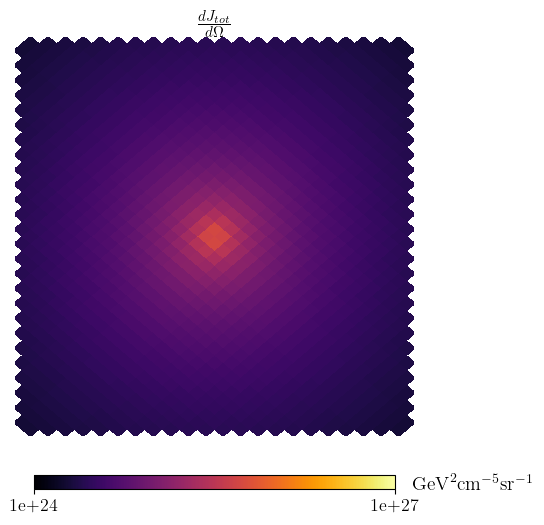

In [12]:
map_CLUMPY = hp.cartview(data_CLUMPY, **opts_CLUMPY)

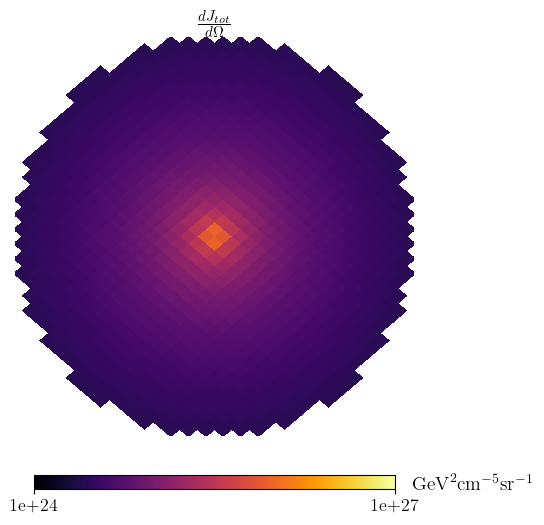

In [13]:
map_computed = hp.cartview(data_computed, **opts_computed)

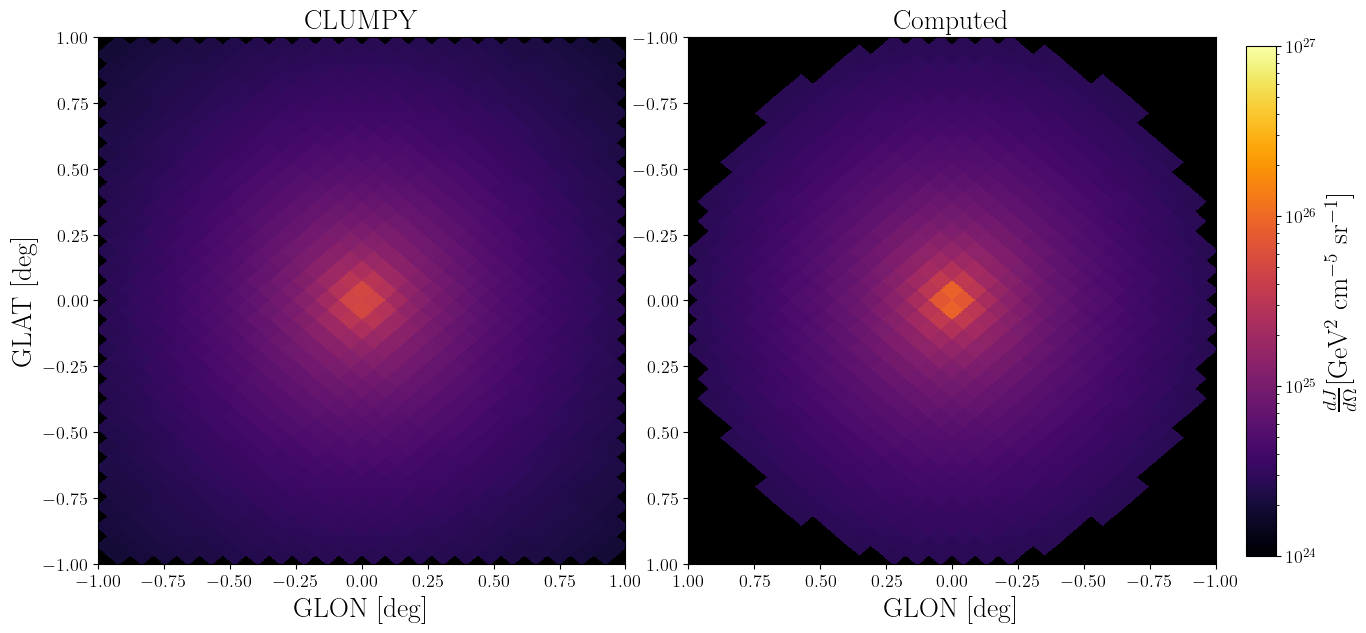

In [14]:
fig, axs = plt.subplots(1,2, figsize=(6*2,6))
fig.tight_layout()

vmin=1e24
vmax=1e27

cent_lat = 0
cent_lon = 0

extent_map_computed = (radius_map_deg+center_halo[0], -radius_map_deg+center_halo[0], radius_map_deg+center_halo[1], -radius_map_deg+center_halo[1])
extent_map_CLUMPY = (lonra[0]+center_halo[0], lonra[1]+center_halo[0], latra[0]+center_halo[1], latra[1]+center_halo[1])

img = axs[0].imshow(map_CLUMPY, origin='lower',
           extent=extent_map_CLUMPY,
           interpolation='none',
           cmap=plt.cm.inferno,
           norm=colors.LogNorm(vmin, vmax))
axs[0].set_ylabel('GLAT [deg]', fontsize = 20)
axs[0].set_xlabel('GLON [deg]', fontsize = 20)
axs[0].set_title('CLUMPY', fontsize = 20)


axs[1].imshow(map_computed, origin='lower',
           extent=extent_map_computed,
           interpolation='none',
           cmap=plt.cm.inferno,
           norm=colors.LogNorm(vmin, vmax))
axs[1].set_title('Computed', fontsize = 20)
axs[1].set_xlabel('GLON [deg]', fontsize = 20)


fig.subplots_adjust(hspace=0.3)
cax = plt.axes([1., 0.09, 0.025, 0.85])
cb = fig.colorbar(img, cax=cax)
cb.set_label(label=r'$\frac{dJ}{d\Omega}$[GeV$^2$ cm$^{-5}$ sr$^{-1}$]', size = 20)
#cb.ax.tick_params(labelsize='large')

for i in [0,1]:
    #axs[i].set_xlim(1, -1)
    #axs[i].set_ylim(-1, 1)

    axs[i].set_facecolor('k')

    
plt.show()


### Pixel to pixel

In [15]:
def radial_samples(data, center_halo):
    # Keep finite, positive values for the logarithmic y-axis.
    ipix = np.flatnonzero(np.isfinite(data) & (data > 0))
    lon, lat = hp.pix2ang(hp.get_nside(data), ipix, lonlat=True)

    alpha_deg = angular_separation(lon * u.deg, lat * u.deg, 
                                   center_halo[0] * u.deg, center_halo[1] * u.deg,).to_value(u.deg)

    return alpha_deg, data[ipix]

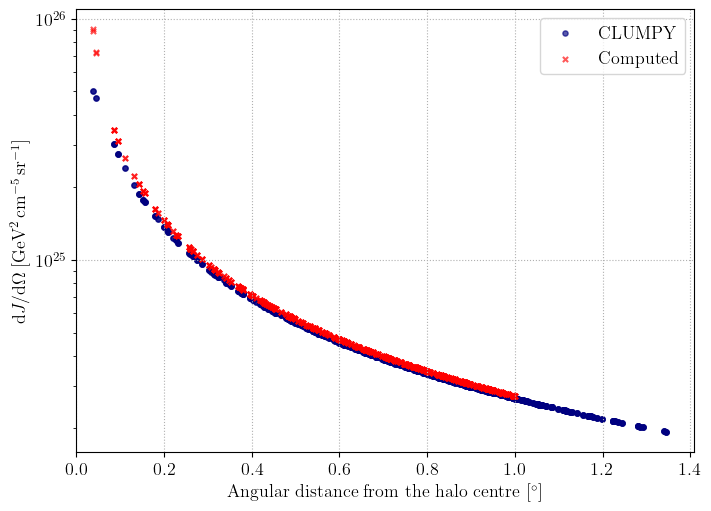

In [16]:
alpha_clumpy, j_clumpy_pixel = radial_samples(data_CLUMPY, center_halo)
alpha_computed, j_computed_pixel = radial_samples(data_computed, center_halo)

fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)

ax.scatter(alpha_clumpy, j_clumpy_pixel, s=14, alpha=0.65, label="CLUMPY", color = 'navy')
ax.scatter(alpha_computed, j_computed_pixel, s=14, alpha=0.65,
           marker="x", color = 'red', label="Computed")

ax.set_xlabel(r"Angular distance from the halo centre [$^\circ$]")
ax.set_ylabel(
    r"$\mathrm{d}J/\mathrm{d}\Omega\;"
    r"[\mathrm{GeV}^{2}\,\mathrm{cm}^{-5}\,\mathrm{sr}^{-1}]$"
)
ax.set_yscale("log")
ax.set_xlim(left=0)
ax.legend()

ax.grid(ls=':')

plt.show()